# Bifidobacterium genus ridge projection + HUNT SNP association

This notebook trains a **genus-level Bifidobacterium lifestyle proxy** in AGP, projects it into UKB, and tests whether the projected UKB phenotype is associated with HUNT microbiome GWAS SNP dosages.

**v3 update:** this version fixes the UKB merge by treating `sample_name` in `ukb_as_agp_metadata.csv` as the UKB participant ID/eid, then explicitly creating `ukb_participant_id = sample_name` before merging with the HUNT SNP dosage table.

Main target for this pilot:

```text
Genus-level Bifidobacterium proxy = log1p(sum of all AGP OTU/ASV counts assigned to Genus == Bifidobacterium)
```

Main SNPs to inspect from the HUNT Table 1 Bifidobacterium species hits:

```text
rs182549_T(/C)   # Bifidobacterium adolescentis signal in HUNT
rs505922_C(/T)   # Bifidobacterium bifidum signal in HUNT
```

Interpretation reminder: this is a **coarse genus-level proxy check**, not a species-level replication.


## 1. Imports

In [1]:
from __future__ import annotations

import json
import re
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)


## 2. Edit paths and settings

Change these paths to match where you run the notebook on the cluster.

In [2]:
# -----------------------------
# Input paths
# -----------------------------
OTU_PATH = Path("./Data/Cleaned_data/AGP_Otu_Data.csv")
METADATA_PATH = Path("./Data/Cleaned_data/processed_metadata.csv")
TAXA_PATH = Path("./Data/Raw_Data/taxa_md5.xls")  # tab-separated text despite .xls extension

# This file is produced by recode_ukb_to_agp.R.
# Important: its `sample_name` column is the UKB participant ID / eid.
UKB_METADATA_PATH = Path("variable_mapping/ukb_as_agp_metadata.csv")
SNP_PATH = Path("./ukb_hunt_table1_effect_allele_dosages.tsv")

# -----------------------------
# Output folder
# -----------------------------
OUT_DIR = Path("./hongrui_result/Bifidobacterium_genus_ridge_snp_test_notebook_v4_id_cleaning")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# -----------------------------
# Index / ID columns
# -----------------------------
METADATA_INDEX = "sample_name"

# In UKB_METADATA_PATH, keep this as a normal column, not as the DataFrame index.
UKB_ID_COL = "sample_name"

# -----------------------------
# CV settings
# -----------------------------
OUTER_SPLITS = 10
INNER_SPLITS = 5
RANDOM_STATE = 42
ALPHAS = np.logspace(-3, 3, 7)

# Optional filter after genus collapse; keep 0.0 for this first pilot.
ABUNDANCE_THRESHOLD = 0.0

# Optional: if you later add UKB genetic PCs to ukb_as_agp_metadata.csv, add them here.
# For a real SNP association, genotype PCs are better than race categories for ancestry control.
GENETIC_PC_COLS = []  # e.g., [f"genetic_pc_{i}" for i in range(1, 11)]


## 3. Helper functions

In [3]:
EXCLUDE_METADATA_COLS = [
    # same idea as your previous ridge/projection workflow: columns that cause major UKB missingness
    "cat",
    "dog",
    "multivitamin",
    "other_supplement_frequency",
    "cosmetics_frequency",
    "fermented_plant_frequency",
    "homecooked_meals_frequency",
    "meat_eggs_frequency",
    "sugary_sweets_frequency",
    "vivid_dreams",
    "sugar_sweetened_drink_frequency",
    "artificial_sweeteners",
    "olive_oil",
    "prepared_meals_frequency",
    "ready_to_eat_meals_frequency",
]

DEFAULT_COVARIATES_NUM = ["age_corrected", "sex"]
DEFAULT_COVARIATES_CAT = ["race", "country_of_birth"]


def make_pipeline(alpha: float) -> Pipeline:
    return Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=float(alpha))),
        ]
    )


def load_tsv_or_csv(path: Path, **kwargs) -> pd.DataFrame:
    """Load CSV/TSV based on extension, with fallback delimiter sniffing."""
    path = Path(path)
    if path.suffix.lower() in {".tsv", ".txt", ".xls"}:
        # taxa_md5.xls in your workflow is usually tab-separated text
        return pd.read_csv(path, sep="\t", **kwargs)
    return pd.read_csv(path, **kwargs)




def normalize_ukb_id(values: pd.Series | list | np.ndarray) -> pd.Series:
    """
    Normalize UKB participant IDs for merging.

    This handles cases where pandas reads IDs from CSV as float-like strings,
    e.g. 1000565.0 -> 1000565, while preserving normal string IDs.
    """
    s = pd.Series(values).copy()

    def _one(v):
        if pd.isna(v):
            return pd.NA
        txt = str(v).strip()
        if txt in {"", "NA", "NaN", "nan", "None", "<NA>", "NULL", "null"}:
            return pd.NA

        # Common case: "1000565.0" or "1000565.000"
        if re.fullmatch(r"\d+\.0+", txt):
            return txt.split(".")[0]

        # Also handle scientific notation or true float objects, if any.
        try:
            f = float(txt)
            if np.isfinite(f) and f.is_integer():
                return str(int(f))
        except Exception:
            pass

        return txt

    return s.map(_one).astype("string")


def clean_taxon_name(x: object) -> str:
    s = str(x).strip()
    # tolerate GTDB/SILVA prefixes if present: g__Bifidobacterium
    s = re.sub(r"^[a-z]__", "", s)
    return s


def find_bifidobacterium_otu_columns(otu_df: pd.DataFrame, taxa_df: pd.DataFrame) -> list[str]:
    """
    Match AGP OTU/ASV table columns to taxonomy rows where Genus == Bifidobacterium.
    Expected taxa table: index = OTU/ASV/md5 ID; contains column 'Genus'.
    """
    if "Genus" not in taxa_df.columns:
        raise ValueError(f"Taxa table must contain a 'Genus' column. Found: {list(taxa_df.columns)}")

    taxa = taxa_df.copy()
    taxa.index = taxa.index.astype(str).str.strip()
    taxa["Genus_clean"] = taxa["Genus"].map(clean_taxon_name)

    bifido_ids = set(taxa.index[taxa["Genus_clean"].str.lower() == "bifidobacterium"])

    # Main case: OTU columns are md5/feature IDs matching taxa index
    matched = [col for col in otu_df.columns if str(col).strip() in bifido_ids]

    # Fallback case: columns were already renamed and contain the genus name
    if len(matched) == 0:
        matched = [col for col in otu_df.columns if "bifidobacterium" in str(col).lower()]

    if len(matched) == 0:
        example_taxa = taxa.loc[taxa["Genus_clean"].str.contains("bifido", case=False, na=False), ["Genus"]].head(20)
        raise ValueError(
            "No OTU columns matched Genus == Bifidobacterium.\n"
            f"Number of taxonomy Bifidobacterium-like rows: {example_taxa.shape[0]}\n"
            f"Examples from taxonomy table:\n{example_taxa.to_string()}"
        )
    return matched


def choose_alpha_nested_cv(
    X: pd.DataFrame,
    y: pd.Series,
    alphas: np.ndarray,
    outer_splits: int = 10,
    inner_splits: int = 5,
    random_state: int = 42,
) -> dict:
    """Nested CV for one target. Returns outer R² and selected alpha information."""
    n = X.shape[0]
    outer_splits = min(outer_splits, n)
    inner_splits = min(inner_splits, max(2, n - 1))

    outer = KFold(n_splits=outer_splits, shuffle=True, random_state=random_state)
    outer_r2 = []
    outer_alphas = []
    fold_predictions = []

    for fold_i, (tr_idx, te_idx) in enumerate(outer.split(X), start=1):
        X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
        y_tr, y_te = y.iloc[tr_idx], y.iloc[te_idx]

        inner = KFold(n_splits=min(inner_splits, len(tr_idx)), shuffle=True, random_state=random_state)
        alpha_scores = []
        for alpha in alphas:
            scores = []
            for itr, iva in inner.split(X_tr):
                pipe = make_pipeline(alpha)
                pipe.fit(X_tr.iloc[itr], y_tr.iloc[itr])
                pred = pipe.predict(X_tr.iloc[iva])
                scores.append(r2_score(y_tr.iloc[iva], pred))
            alpha_scores.append(float(np.mean(scores)))

        best_alpha = float(alphas[int(np.argmax(alpha_scores))])
        outer_alphas.append(best_alpha)

        pipe = make_pipeline(best_alpha)
        pipe.fit(X_tr, y_tr)
        pred_te = pipe.predict(X_te)
        fold_r2 = float(r2_score(y_te, pred_te))
        outer_r2.append(fold_r2)

        fold_predictions.append(
            pd.DataFrame(
                {
                    "fold": fold_i,
                    "sample_name": X_te.index.astype(str),
                    "y_true": y_te.values,
                    "y_pred": pred_te,
                    "best_alpha": best_alpha,
                    "fold_r2": fold_r2,
                }
            )
        )

        print(f"outer fold {fold_i:02d}: R2={fold_r2: .4f}, alpha={best_alpha:g}")

    alpha_mode = float(pd.Series(outer_alphas).mode().iloc[0])
    return {
        "outer_r2_scores": outer_r2,
        "outer_r2_mean": float(np.mean(outer_r2)),
        "outer_r2_std": float(np.std(outer_r2, ddof=1)),
        "outer_best_alphas": outer_alphas,
        "outer_best_alpha_mode": alpha_mode,
        "fold_predictions": pd.concat(fold_predictions, ignore_index=True) if fold_predictions else None,
    }


def parse_effect_allele_from_col(col: str) -> str | None:
    # Example: rs182549_T(/C) -> T
    m = re.search(r"_([ACGT])\(/([ACGT])\)", str(col))
    if m:
        return m.group(1)
    return None


def build_covariates(
    df: pd.DataFrame,
    cov_num: list[str],
    cov_cat: list[str],
    genetic_pc_cols: list[str] | None = None,
) -> pd.DataFrame:
    genetic_pc_cols = genetic_pc_cols or []
    parts = []

    numeric_cols = [c for c in cov_num + genetic_pc_cols if c in df.columns]
    if numeric_cols:
        parts.append(df[numeric_cols].apply(pd.to_numeric, errors="coerce"))

    cat_cols = [c for c in cov_cat if c in df.columns]
    if cat_cols:
        parts.append(
            pd.get_dummies(
                df[cat_cols].astype("string").fillna("MISSING"),
                prefix=cat_cols,
                drop_first=True,
                dtype=float,
            )
        )

    if not parts:
        return pd.DataFrame(index=df.index)
    return pd.concat(parts, axis=1)


def get_one_numeric_column(df: pd.DataFrame, col: str, label: str | None = None) -> pd.Series:
    """
    Safely extract one numeric column.

    If df has duplicate column names, df.loc[:, col] returns a 2D DataFrame
    instead of a 1D Series. This keeps only the first copy and warns you.
    """
    label = label or col
    if col not in df.columns:
        raise KeyError(f"Column not found: {col}")

    x = df.loc[:, col]
    if isinstance(x, pd.DataFrame):
        print(f"Warning: {label} matched {x.shape[1]} columns; using the first copy.")
        x = x.iloc[:, 0]

    return pd.to_numeric(pd.Series(x).squeeze(), errors="coerce")


def empty_snp_result_row(snp: str, n: int, reason: str) -> dict:
    """Return a row with all expected result columns, even when a model cannot be fit."""
    return {
        "snp": snp,
        "n": int(n),
        "effect_allele_from_column": parse_effect_allele_from_col(snp),
        "beta_per_effect_allele": np.nan,
        "se_hc3": np.nan,
        "t_hc3": np.nan,
        "p_value": np.nan,
        "q_value_BH": np.nan,
        "r2": np.nan,
        "pearson_r_raw": np.nan,
        "pearson_p_raw": np.nan,
        "error": reason,
    }


def diagnose_snp_inputs(
    merged: pd.DataFrame,
    snp_cols: list[str],
    y_col: str = "bifidobacterium_genus_hat",
) -> pd.DataFrame:
    """Summarize usable rows for each SNP before model fitting."""
    y = get_one_numeric_column(merged, y_col, label="outcome").reset_index(drop=True)
    rows = []
    for snp in list(dict.fromkeys(snp_cols)):
        g = get_one_numeric_column(merged, snp, label=snp).reset_index(drop=True)
        tmp = pd.concat([y.rename("y"), g.rename("snp")], axis=1).replace([np.inf, -np.inf], np.nan)
        complete = tmp.dropna()
        rows.append({
            "snp": snp,
            "merged_rows": merged.shape[0],
            "nonmissing_y": int(tmp["y"].notna().sum()),
            "nonmissing_snp": int(tmp["snp"].notna().sum()),
            "complete_y_and_snp": int(complete.shape[0]),
            "snp_unique_complete": int(complete["snp"].nunique()) if complete.shape[0] else 0,
            "snp_min_complete": float(complete["snp"].min()) if complete.shape[0] else np.nan,
            "snp_max_complete": float(complete["snp"].max()) if complete.shape[0] else np.nan,
        })
    return pd.DataFrame(rows)


def fit_snp_models(
    merged: pd.DataFrame,
    snp_cols: list[str],
    y_col: str,
    cov_df: pd.DataFrame | None = None,
    min_n: int = 100,
) -> pd.DataFrame:
    rows = []

    # Remove duplicate SNP names from the testing list while preserving order.
    snp_cols = list(dict.fromkeys(snp_cols))

    # Use one clean 1D y vector. Reset index so all objects concatenate by row position.
    y = get_one_numeric_column(merged, y_col, label="outcome").rename("y").reset_index(drop=True)

    if cov_df is None or cov_df.shape[1] == 0:
        cov_clean = None
    else:
        cov_clean = cov_df.copy()
        cov_clean = cov_clean.loc[:, ~cov_clean.columns.duplicated()].reset_index(drop=True)
        cov_clean = cov_clean.apply(pd.to_numeric, errors="coerce")

    for snp in snp_cols:
        try:
            g = get_one_numeric_column(merged, snp, label=snp).rename("snp").reset_index(drop=True)

            parts = [y, g]
            if cov_clean is not None:
                parts.append(cov_clean)

            model_df = pd.concat(parts, axis=1)
            model_df = model_df.replace([np.inf, -np.inf], np.nan).dropna()

            if model_df.shape[0] < min_n:
                rows.append(empty_snp_result_row(
                    snp,
                    model_df.shape[0],
                    f"too few complete rows after dropping missing values; need at least {min_n}",
                ))
                continue

            if model_df["snp"].nunique() < 2:
                rows.append(empty_snp_result_row(
                    snp,
                    model_df.shape[0],
                    "no SNP dosage variation among complete rows",
                ))
                continue

            X = model_df.drop(columns="y").astype(float)
            X = sm.add_constant(X, has_constant="add")
            fit = sm.OLS(model_df["y"].astype(float), X).fit(cov_type="HC3")

            r, rp = stats.pearsonr(model_df["snp"], model_df["y"])

            rows.append({
                "snp": snp,
                "n": int(fit.nobs),
                "effect_allele_from_column": parse_effect_allele_from_col(snp),
                "beta_per_effect_allele": float(fit.params["snp"]),
                "se_hc3": float(fit.bse["snp"]),
                "t_hc3": float(fit.tvalues["snp"]),
                "p_value": float(fit.pvalues["snp"]),
                "q_value_BH": np.nan,
                "r2": float(fit.rsquared),
                "pearson_r_raw": float(r),
                "pearson_p_raw": float(rp),
                "error": "",
            })
        except Exception as e:
            rows.append(empty_snp_result_row(snp, 0, f"model fitting error: {type(e).__name__}: {e}"))

    out = pd.DataFrame(rows)

    # Multiple-testing correction only for successfully fit rows.
    if "p_value" in out.columns and out["p_value"].notna().any():
        ok = out["p_value"].notna()
        _, q, _, _ = multipletests(out.loc[ok, "p_value"], method="fdr_bh")
        out.loc[ok, "q_value_BH"] = q
        return out.sort_values("p_value", na_position="last")

    print("No SNP model was successfully fit. Check the 'error' column and the diagnostics table.")
    return out


## 4. Load AGP metadata, OTU/ASV table, and taxonomy

In [4]:
metadata_df = pd.read_csv(METADATA_PATH, index_col=METADATA_INDEX)
otu_df = pd.read_csv(OTU_PATH, index_col=0)
taxa_df = load_tsv_or_csv(TAXA_PATH, index_col=0)

metadata_df.index = metadata_df.index.astype(str)
otu_df.index = otu_df.index.astype(str)
otu_df.columns = otu_df.columns.astype(str).str.strip()

common = metadata_df.index.intersection(otu_df.index)
if len(common) == 0:
    raise ValueError("No overlapping sample IDs between metadata and OTU table.")

metadata_df = metadata_df.loc[common].copy()
otu_df = otu_df.loc[common].copy()

print(f"Aligned AGP samples: {len(common)}")
print(f"AGP OTU/ASV table shape: {otu_df.shape}")
print(f"AGP metadata shape: {metadata_df.shape}")
taxa_df.head()


Aligned AGP samples: 9559
AGP OTU/ASV table shape: (9559, 4460)
AGP metadata shape: (9559, 48)


,Kingdom,Phylum,Class,Order,Family,Genus,OTU
ef63210b495a2604f8a624c1dc463967,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Bacteroidaceae,Bacteroides,TACGGAGGATCCGAGCGTTATCCGGATTTATTGGGTTTAAAGGGAG...
fee9d92edb4dcf51e6ac35e0c68647f0,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Bacteroidaceae,Bacteroides,TACGGAGGATCCGAGCGTTATCCGGATTTATTGGGTTTAAAGGGAG...
26beb3295e398c95d786ef5c439691e0,Bacteria,Firmicutes,Clostridia,Clostridiales,Ruminococcaceae,Faecalibacterium,AACGTAGGTCACAAGCGTTGTCCGGAATTACTGGGTGTAAAGGGAG...
48645283f7e325b651305bed98b7f1cd,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Bacteroidaceae,Bacteroides,TACGGAGGATCCGAGCGTTATCCGGATTTATTGGGTTTAAAGGGAG...
6bfe71f580ccfa342a0ddd97cb0f4170,Bacteria,Firmicutes,Clostridia,Clostridiales,Ruminococcaceae,Faecalibacterium,AACGTAGGTCACAAGCGTTGTCCGGAATTACTGGGTGTAAAGGGAG...


## 5. Collapse Bifidobacterium OTUs/ASVs to genus-level target

This sums all raw-count OTU/ASV columns assigned to `Genus == Bifidobacterium`, then applies `log1p` to the summed count.

In [5]:
bifido_cols = find_bifidobacterium_otu_columns(otu_df, taxa_df)
print(f"Matched Bifidobacterium OTU/ASV columns: {len(bifido_cols)}")

pd.Series(bifido_cols, name="bifidobacterium_otu_columns").to_csv(
    OUT_DIR / "bifidobacterium_otu_columns_used.csv", index=False
)

# Correct genus-level target: sum raw counts first, THEN transform.
bifido_counts = otu_df[bifido_cols].apply(pd.to_numeric, errors="coerce").fillna(0).sum(axis=1)
total_counts = otu_df.apply(pd.to_numeric, errors="coerce").fillna(0).sum(axis=1)
rel_abund = bifido_counts / total_counts.replace(0, np.nan)

mean_rel = float(rel_abund.mean())
prevalence = float((bifido_counts > 0).mean())

y = np.log1p(bifido_counts).rename("log1p_Bifidobacterium_genus_count")

print(f"Bifidobacterium genus mean relative abundance: {mean_rel:.6g}")
print(f"Bifidobacterium genus prevalence: {prevalence:.3f}")
print(y.describe())

if mean_rel < ABUNDANCE_THRESHOLD:
    raise ValueError("Bifidobacterium mean relative abundance is below threshold.")

pd.DataFrame({
    "sample_name": y.index,
    "bifidobacterium_raw_count_sum": bifido_counts.values,
    "bifidobacterium_relative_abundance": rel_abund.values,
    "log1p_Bifidobacterium_genus_count": y.values,
}).to_csv(OUT_DIR / "agp_bifidobacterium_genus_target.csv", index=False)


Matched Bifidobacterium OTU/ASV columns: 14
Bifidobacterium genus mean relative abundance: 0.0115496
Bifidobacterium genus prevalence: 0.759
count    9559.000000
mean        2.824141
std         2.105002
min         0.000000
25%         0.693147
50%         2.995732
75%         4.436734
max         9.118664
Name: log1p_Bifidobacterium_genus_count, dtype: float64


## 6. Build lifestyle predictor matrix

In [6]:
numeric_cols_all = metadata_df.select_dtypes(include=np.number).columns.tolist()
train_cols = [c for c in numeric_cols_all if c not in set(EXCLUDE_METADATA_COLS)]
X = metadata_df[train_cols].copy()

print(f"Training predictors: {X.shape[1]} numeric AGP lifestyle/metadata variables")
print(f"Training samples: {X.shape[0]}")

pd.DataFrame({"train_cols": train_cols}).to_csv(OUT_DIR / "ridge_training_columns.csv", index=False)
X.head()


Training predictors: 29 numeric AGP lifestyle/metadata variables
Training samples: 9559


,alcohol_consumption,appendix_removed,lactose,alcohol_frequency,exercise_frequency,flossing_frequency,frozen_dessert_frequency,fruit_frequency,high_fat_red_meat_frequency,milk_cheese_frequency,milk_substitute_frequency,one_liter_of_water_a_day_frequency,poultry_frequency,probiotic_frequency,red_meat_frequency,salted_snacks_frequency,seafood_frequency,smoking_frequency,teethbrushing_frequency,vegetable_frequency,vitamin_b_supplement_frequency,vitamin_d_supplement_frequency,whole_eggs,whole_grain_frequency,bowel_movement_frequency,sleep_duration,sex,bmi,weight_kg
ERR1073439,1,0,0,1,2,0,5,5,5,5,5,5,5,5,5,5,5,0,4,5,5,5,5,5,1,6,0,35.92,110.0
ERR1072625,1,0,0,1,2,2,5,5,5,5,5,5,5,5,5,5,5,0,4,5,5,5,5,5,1,8,1,34.89,86.0
ERR1089664,1,0,0,1,4,3,5,5,5,5,5,5,5,5,5,5,5,0,4,5,5,5,5,5,1,6,0,22.50,77.0
ERR1075599,1,0,0,3,3,3,5,5,5,5,5,5,5,5,5,5,5,1,4,5,5,5,5,5,1,8,0,23.08,79.0
ERR1073066,1,0,1,1,2,1,5,5,5,5,5,5,5,5,5,5,5,0,4,5,5,5,5,5,1,10,1,21.08,56.0


## 7. Nested cross-validation for ridge model

In [7]:
cv_info = choose_alpha_nested_cv(
    X=X,
    y=y,
    alphas=ALPHAS,
    outer_splits=OUTER_SPLITS,
    inner_splits=INNER_SPLITS,
    random_state=RANDOM_STATE,
)

print(f"Nested-CV R2 mean ± SD: {cv_info['outer_r2_mean']:.4f} ± {cv_info['outer_r2_std']:.4f}")
print(f"Alpha mode: {cv_info['outer_best_alpha_mode']:g}")

cv_summary = pd.DataFrame({
    "fold": np.arange(1, len(cv_info["outer_r2_scores"]) + 1),
    "outer_r2": cv_info["outer_r2_scores"],
    "best_alpha": cv_info["outer_best_alphas"],
})
cv_summary.to_csv(OUT_DIR / "nested_cv_summary.csv", index=False)

if cv_info["fold_predictions"] is not None:
    cv_info["fold_predictions"].to_csv(OUT_DIR / "nested_cv_fold_predictions.csv", index=False)

cv_summary


outer fold 01: R2= 0.1173, alpha=100
outer fold 02: R2= 0.0999, alpha=100
outer fold 03: R2= 0.1283, alpha=100
outer fold 04: R2= 0.1123, alpha=100
outer fold 05: R2= 0.0979, alpha=100
outer fold 06: R2= 0.1108, alpha=100
outer fold 07: R2= 0.1139, alpha=100
outer fold 08: R2= 0.0658, alpha=100
outer fold 09: R2= 0.0945, alpha=100
outer fold 10: R2= 0.1106, alpha=100
Nested-CV R2 mean ± SD: 0.1051 ± 0.0171
Alpha mode: 100


,fold,outer_r2,best_alpha
0,1,0.117312,100.0
1,2,0.099880,100.0
2,3,0.128296,100.0
3,4,0.112267,100.0
4,5,0.097919,100.0
5,6,0.110787,100.0
6,7,0.113894,100.0
7,8,0.065771,100.0
8,9,0.094459,100.0
9,10,0.110570,100.0


## 8. Fit final AGP model and project Bifidobacterium genus proxy into UKB

In [8]:
final_model = make_pipeline(cv_info["outer_best_alpha_mode"])
final_model.fit(X, y)
joblib.dump(final_model, OUT_DIR / "bifidobacterium_genus_ridge_model.pkl")

model_meta = {
    "target": "log1p(sum raw AGP counts for Genus == Bifidobacterium)",
    "n_bifidobacterium_otu_columns": len(bifido_cols),
    "bifidobacterium_prevalence": prevalence,
    "bifidobacterium_mean_relative_abundance": mean_rel,
    "train_cols": train_cols,
    "excluded_metadata_cols": EXCLUDE_METADATA_COLS,
    "alphas": [float(a) for a in ALPHAS],
    "cv": {k: v for k, v in cv_info.items() if k != "fold_predictions"},
}
with open(OUT_DIR / "bifidobacterium_genus_ridge_metadata.json", "w") as f:
    json.dump(model_meta, f, indent=2)

# ------------------------------------------------------------------
# Load UKB metadata WITHOUT setting sample_name as index.
# sample_name is the UKB participant ID / eid and must be carried forward.
# ------------------------------------------------------------------
ukb_df = pd.read_csv(UKB_METADATA_PATH)

if UKB_ID_COL not in ukb_df.columns:
    raise ValueError(
        f"Expected UKB ID column '{UKB_ID_COL}' in {UKB_METADATA_PATH}. "
        f"Available columns include: {list(ukb_df.columns[:20])}"
    )

ukb_df[UKB_ID_COL] = normalize_ukb_id(ukb_df[UKB_ID_COL])

# Prepare UKB predictor matrix using the same training columns as AGP.
# Missing columns are added as all-NA and handled by the model imputer.
X_ukb = ukb_df.reindex(columns=train_cols).apply(pd.to_numeric, errors="coerce")

missing_train_cols = [c for c in train_cols if c not in ukb_df.columns]
print(f"UKB rows: {X_ukb.shape[0]}")
print(f"UKB missing training columns: {len(missing_train_cols)} / {len(train_cols)}")
if missing_train_cols:
    print("First missing training columns:", missing_train_cols[:20])

ukb_pred = final_model.predict(X_ukb)

pred_df = pd.DataFrame(
    {
        "ukb_participant_id": normalize_ukb_id(ukb_df[UKB_ID_COL]),
        "bifidobacterium_genus_hat": ukb_pred,
    }
)

# Remove accidental blank IDs if present.
pred_df = pred_df[pred_df["ukb_participant_id"].notna() & (pred_df["ukb_participant_id"] != "")].copy()

pred_df.to_csv(OUT_DIR / "ukb_bifidobacterium_genus_hat.csv", index=False)
print("Example normalized projected IDs:", pred_df["ukb_participant_id"].head().tolist())
print(pred_df.head())
print(pred_df.shape)


UKB rows: 502244
UKB missing training columns: 0 / 29
Example normalized projected IDs: ['1000565', '1004472', '1005221', '1006556', '1006792']
  ukb_participant_id  bifidobacterium_genus_hat
0            1000565                   4.169046
1            1004472                   3.441833
2            1005221                   3.318720
3            1006556                   2.343680
4            1006792                   2.905715
(502244, 2)


## 9. Load HUNT SNP dosage table and merge with projected phenotype

In [9]:
snp_df = pd.read_csv(SNP_PATH, sep="	")

if "ukb_participant_id" not in snp_df.columns:
    if "FID" in snp_df.columns:
        snp_df["ukb_participant_id"] = snp_df["FID"]
    else:
        raise ValueError("SNP file needs 'ukb_participant_id' or 'FID'.")

# Force IDs to the same cleaned string format before merging.
# This removes float artifacts such as "1000565.0" -> "1000565".
snp_df["ukb_participant_id"] = normalize_ukb_id(snp_df["ukb_participant_id"])
pred_df["ukb_participant_id"] = normalize_ukb_id(pred_df["ukb_participant_id"])

id_overlap = len(set(pred_df["ukb_participant_id"]) & set(snp_df["ukb_participant_id"]))
print("pred_df rows:", pred_df.shape[0])
print("snp_df rows:", snp_df.shape[0])
print("ID overlap:", id_overlap)
print("Example cleaned pred_df IDs:", pred_df["ukb_participant_id"].head().tolist())
print("Example cleaned snp_df IDs:", snp_df["ukb_participant_id"].head().tolist())

if id_overlap == 0:
    print("Example pred_df IDs:", pred_df["ukb_participant_id"].head().tolist())
    print("Example snp_df IDs:", snp_df["ukb_participant_id"].head().tolist())
    raise ValueError("No overlap between projected UKB IDs and SNP dosage IDs. Check UKB_ID_COL and SNP ID formatting.")

merged = pred_df.merge(
    snp_df,
    on="ukb_participant_id",
    how="inner",
)

# Add UKB covariates for merged participants.
# Here ukb_df still has sample_name as a normal column, so build the same ID column explicitly.
ukb_cov = ukb_df.copy()
ukb_cov["ukb_participant_id"] = normalize_ukb_id(ukb_cov[UKB_ID_COL])

covariate_cols_to_keep = [
    c for c in DEFAULT_COVARIATES_NUM + DEFAULT_COVARIATES_CAT + GENETIC_PC_COLS
    if c in ukb_cov.columns
]

merged = merged.merge(
    ukb_cov[["ukb_participant_id"] + covariate_cols_to_keep],
    on="ukb_participant_id",
    how="left",
)

print(f"Merged UKB predicted phenotype + SNP dosages: {merged.shape[0]} rows")
print(f"Covariates available: {covariate_cols_to_keep}")

merged.to_csv(OUT_DIR / "merged_bifidobacterium_hat_hunt_snps.csv", index=False)
merged.head()


pred_df rows: 502244
snp_df rows: 425630
ID overlap: 425532
Example cleaned pred_df IDs: ['1000565', '1004472', '1005221', '1006556', '1006792']
Example cleaned snp_df IDs: ['1000011', '1000026', '1000032', '1000044', '1000058']
Merged UKB predicted phenotype + SNP dosages: 425532 rows
Covariates available: ['age_corrected', 'sex', 'race', 'country_of_birth']


,ukb_participant_id,bifidobacterium_genus_hat,FID,rs182549_T(/C),rs28407950_T(/C),rs4556017_T(/C),rs644234_G(/T),rs550057_T(/C),rs505922_C(/T),rs73024305_C(/G),rs35106244_T(/C),rs4002471_T(/C),rs35866622_T(/C),rs2287921_C(/T),age_corrected,sex,race,country_of_birth
0,1004472,3.441833,1004472,1.9921,0.0,1.0039,1.0,1.0,1,0.0,1.0,1.0000,1.00000,1,41,0,Caucasian,United Kingdom
1,1005221,3.318720,1005221,2.0000,0.0,1.0000,1.0,1.0,1,0.0,0.0,0.0000,0.00000,0,66,1,Caucasian,United Kingdom
2,1006556,2.343680,1006556,1.0000,0.0,2.0000,0.0,0.0,0,0.0,0.0,0.0000,0.00000,0,56,0,Caucasian,United Kingdom
3,1006792,2.905715,1006792,1.0000,0.0,2.0000,1.0,1.0,1,0.0,1.0,2.0000,1.00000,2,65,1,Caucasian,United Kingdom
4,1006976,3.355561,1006976,2.0000,0.0,2.0000,0.0,0.0,0,1.0,0.0,0.0902,0.50586,1,61,1,Caucasian,United Kingdom


## 10. SNP association tests

Model 1 is raw/unadjusted:

```text
projected_Bifidobacterium_genus ~ SNP dosage
```

Model 2 is covariate-adjusted:

```text
projected_Bifidobacterium_genus ~ SNP dosage + age + sex + race + country_of_birth
```

Add genetic PCs to `GENETIC_PC_COLS` when you have them in `ukb_as_agp_metadata.csv`.

In [10]:
snp_cols = [c for c in snp_df.columns if c not in {"FID", "ukb_participant_id"}]
print(f"SNP columns to test: {len(snp_cols)}")

# Diagnostics before model fitting.
print(f"Merged rows: {merged.shape[0]}")
print(f"Non-missing projected Bifidobacterium values: {merged['bifidobacterium_genus_hat'].notna().sum()}")

dup_cols = merged.columns[merged.columns.duplicated()].tolist()
if dup_cols:
    print("Duplicate columns in merged:", dup_cols)

input_diag = diagnose_snp_inputs(
    merged=merged,
    snp_cols=snp_cols,
    y_col="bifidobacterium_genus_hat",
)
input_diag.to_csv(OUT_DIR / "snp_input_diagnostics.csv", index=False)
display(input_diag)

# Raw SNP association with projected genus proxy.
raw_results = fit_snp_models(
    merged=merged,
    snp_cols=snp_cols,
    y_col="bifidobacterium_genus_hat",
    cov_df=None,
)
raw_results.to_csv(OUT_DIR / "snp_association_raw.csv", index=False)
display(raw_results)

# Covariate-adjusted. Add genotype PCs to GENETIC_PC_COLS when available.
cov_df = build_covariates(
    merged,
    cov_num=DEFAULT_COVARIATES_NUM,
    cov_cat=DEFAULT_COVARIATES_CAT,
    genetic_pc_cols=GENETIC_PC_COLS,
)

adjusted_results = fit_snp_models(
    merged=merged,
    snp_cols=snp_cols,
    y_col="bifidobacterium_genus_hat",
    cov_df=cov_df,
)
adjusted_results.to_csv(OUT_DIR / "snp_association_covariate_adjusted.csv", index=False)

# Convenience file: just the HUNT Bifidobacterium-related SNPs if present.
bifido_hunt_snps = ["rs182549_T(/C)", "rs505922_C(/T)"]
bifido_only = adjusted_results[adjusted_results["snp"].isin(bifido_hunt_snps)].copy()
bifido_only.to_csv(OUT_DIR / "snp_association_Bifidobacterium_HUNT_only.csv", index=False)

display(adjusted_results.head(20))


SNP columns to test: 11
Merged rows: 425532
Non-missing projected Bifidobacterium values: 425532


,snp,merged_rows,nonmissing_y,nonmissing_snp,complete_y_and_snp,snp_unique_complete,snp_min_complete,snp_max_complete
0,rs182549_T(/C),425532,425532,425532,425532,511,0.0,2.0
1,rs28407950_T(/C),425532,425532,425532,425532,337,0.0,2.0
2,rs4556017_T(/C),425532,425532,425532,425532,504,0.0,2.0
3,rs644234_G(/T),425532,425532,425532,425532,35,0.0,2.0
4,rs550057_T(/C),425532,425532,425532,425532,197,0.0,2.0
5,rs505922_C(/T),425532,425532,425532,425532,3,0.0,2.0
6,rs73024305_C(/G),425532,425532,425532,425532,275,0.0,2.0
7,rs35106244_T(/C),425532,425532,425532,425532,511,0.0,2.0
8,rs4002471_T(/C),425532,425532,425532,425532,502,0.0,2.0
9,rs35866622_T(/C),425532,425532,425532,425532,510,0.0,2.0


,snp,n,effect_allele_from_column,beta_per_effect_allele,se_hc3,t_hc3,p_value,q_value_BH,r2,pearson_r_raw,pearson_p_raw,error
9,rs35866622_T(/C),425532,T,0.016678,0.001333,12.509223,6.647115e-36,7.311827e-35,3.676306e-04,0.019174,6.694864e-36,
10,rs2287921_C(/T),425532,C,0.016544,0.001331,12.431141,1.770894e-35,9.739919e-35,3.632037e-04,0.019058,1.728016e-35,
8,rs4002471_T(/C),425532,T,0.016074,0.001337,12.025685,2.604208e-33,9.548764e-33,3.395354e-04,0.018426,2.752823e-33,
7,rs35106244_T(/C),425532,T,0.015237,0.001368,11.137018,8.284711e-29,2.278296e-28,2.915290e-04,0.017074,8.122967e-29,
0,rs182549_T(/C),425532,T,0.012983,0.001558,8.332186,7.936313e-17,1.745989e-16,1.625248e-04,0.012749,9.057301e-17,
4,rs550057_T(/C),425532,T,-0.011670,0.001520,-7.675824,1.643593e-14,3.013253e-14,1.384423e-04,-0.011766,1.646033e-14,
5,rs505922_C(/T),425532,C,-0.010056,0.001427,-7.045472,1.848337e-12,2.904529e-12,1.167952e-04,-0.010807,1.788986e-12,
3,rs644234_G(/T),425532,G,-0.009771,0.001401,-6.972962,3.103357e-12,4.267116e-12,1.142727e-04,-0.010690,3.092342e-12,
1,rs28407950_T(/C),425532,T,-0.002964,0.001543,-1.920402,5.480710e-02,6.698645e-02,8.623656e-06,-0.002937,5.541230e-02,
2,rs4556017_T(/C),425532,T,0.001519,0.001883,0.806400,4.200121e-01,4.620134e-01,1.533847e-06,0.001238,4.191499e-01,


,snp,n,effect_allele_from_column,beta_per_effect_allele,se_hc3,t_hc3,p_value,q_value_BH,r2,pearson_r_raw,pearson_p_raw,error
9,rs35866622_T(/C),425532,T,0.016817,0.001327,12.671021,8.559325e-37,9.415258e-36,0.009657,0.019174,6.694864e-36,
10,rs2287921_C(/T),425532,C,0.016688,0.001325,12.597019,2.192764e-36,1.206020e-35,0.009652,0.019058,1.728016e-35,
8,rs4002471_T(/C),425532,T,0.016202,0.001331,12.176685,4.137602e-34,1.517121e-33,0.009628,0.018426,2.752823e-33,
7,rs35106244_T(/C),425532,T,0.015521,0.001362,11.394519,4.452813e-30,1.224524e-29,0.009585,0.017074,8.122967e-29,
0,rs182549_T(/C),425532,T,0.012562,0.001552,8.096300,5.665594e-16,1.246431e-15,0.009435,0.012749,9.057301e-17,
4,rs550057_T(/C),425532,T,-0.011460,0.001514,-7.569284,3.752867e-14,6.880257e-14,0.009416,-0.011766,1.646033e-14,
5,rs505922_C(/T),425532,C,-0.009796,0.001421,-6.892607,5.477925e-12,8.608168e-12,0.009394,-0.010807,1.788986e-12,
3,rs644234_G(/T),425532,G,-0.009435,0.001395,-6.762504,1.356270e-11,1.864871e-11,0.009389,-0.010690,3.092342e-12,
1,rs28407950_T(/C),425532,T,-0.002789,0.001537,-1.815031,6.951920e-02,8.496791e-02,0.009290,-0.002937,5.541230e-02,
2,rs4556017_T(/C),425532,T,0.001227,0.001875,0.654555,5.127543e-01,5.640298e-01,0.009284,0.001238,4.191499e-01,


## 11. Focused output: HUNT Bifidobacterium SNPs

In [12]:
display_cols = [
    c for c in [
        "snp",
        "n",
        "effect_allele_from_column",
        "beta_per_effect_allele",
        "se_hc3",
        "p_value",
        "q_value_BH",
        "pearson_r_raw",
    ]
    if c in adjusted_results.columns
]

print("HUNT Bifidobacterium species SNPs tested against your projected genus proxy:")
display(bifido_only[display_cols])

print("Expected rough direction if the genus proxy captures the HUNT species signal:")
print("  rs182549_T(/C): negative beta; HUNT T allele lower B. adolescentis")
print("  rs505922_C(/T): negative beta; HUNT C allele lower B. bifidum")


HUNT Bifidobacterium species SNPs tested against your projected genus proxy:


,snp,n,effect_allele_from_column,beta_per_effect_allele,se_hc3,p_value,q_value_BH,pearson_r_raw
0,rs182549_T(/C),425532,T,0.012562,0.001552,5.665594e-16,1.246431e-15,0.012749
5,rs505922_C(/T),425532,C,-0.009796,0.001421,5.477925e-12,8.608168e-12,-0.010807


Expected rough direction if the genus proxy captures the HUNT species signal:
  rs182549_T(/C): negative beta; HUNT T allele lower B. adolescentis
  rs505922_C(/T): negative beta; HUNT C allele lower B. bifidum


## 12. Optional: simple scatter plots for the two Bifidobacterium SNPs

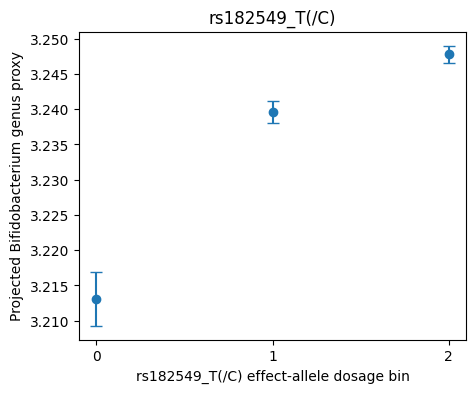

,mean,sem,count
dosage_bin,,,
0,3.213123,0.003810,25513
1,3.239573,0.001549,155908
2,3.247779,0.001241,244111


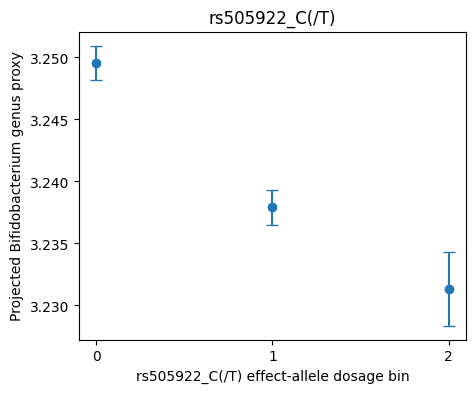

,mean,sem,count
dosage_bin,,,
0,3.249579,0.001373,198762
1,3.237898,0.001428,183995
2,3.231341,0.002967,42775


In [13]:
import matplotlib.pyplot as plt

for snp in ["rs182549_T(/C)", "rs505922_C(/T)"]:
    if snp not in merged.columns:
        print(f"Skipping {snp}: not found in merged table")
        continue

    plot_df = merged[[snp, "bifidobacterium_genus_hat"]].copy()
    plot_df[snp] = pd.to_numeric(plot_df[snp], errors="coerce")
    plot_df["bifidobacterium_genus_hat"] = pd.to_numeric(plot_df["bifidobacterium_genus_hat"], errors="coerce")
    plot_df = plot_df.dropna()

    # For imputed dosage, many values are fractional. Bin dosage for clearer visualization.
    plot_df["dosage_bin"] = pd.cut(plot_df[snp], bins=[-0.01, 0.5, 1.5, 2.01], labels=["0", "1", "2"])
    summary = plot_df.groupby("dosage_bin", observed=True)["bifidobacterium_genus_hat"].agg(["mean", "sem", "count"])

    plt.figure(figsize=(5, 4))
    plt.errorbar(summary.index.astype(str), summary["mean"], yerr=summary["sem"], fmt="o", capsize=4)
    plt.xlabel(f"{snp} effect-allele dosage bin")
    plt.ylabel("Projected Bifidobacterium genus proxy")
    plt.title(snp)
    plt.show()

    display(summary)


## 13. Output files created

After running the full notebook, check these files:

```text
bifidobacterium_otu_columns_used.csv
agp_bifidobacterium_genus_target.csv
ridge_training_columns.csv
nested_cv_summary.csv
nested_cv_fold_predictions.csv
bifidobacterium_genus_ridge_model.pkl
bifidobacterium_genus_ridge_metadata.json
ukb_bifidobacterium_genus_hat.csv
merged_bifidobacterium_hat_hunt_snps.csv
snp_association_raw.csv
snp_association_covariate_adjusted.csv
snp_association_Bifidobacterium_HUNT_only.csv
```


geno_group
0     25513
1    155908
2    244111
Name: count, dtype: int64


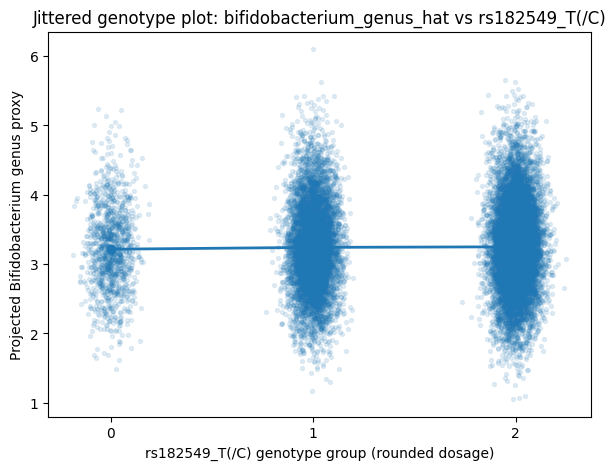

geno_group
0    3.213123
1    3.239573
2    3.247779
Name: bifidobacterium_genus_hat, dtype: float64


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SNP = "rs182549_T(/C)"
YCOL = "bifidobacterium_genus_hat"

plot_df = merged[[SNP, YCOL]].copy()
plot_df[SNP] = pd.to_numeric(plot_df[SNP], errors="coerce")
plot_df[YCOL] = pd.to_numeric(plot_df[YCOL], errors="coerce")
plot_df = plot_df.dropna()

# Round imputed dosage to nearest genotype group: 0, 1, 2
plot_df["geno_group"] = np.rint(plot_df[SNP]).astype(int)
plot_df = plot_df[plot_df["geno_group"].isin([0, 1, 2])]

print(plot_df["geno_group"].value_counts().sort_index())

# Sample for plotting
N_PLOT = 20000
if plot_df.shape[0] > N_PLOT:
    plot_df_plot = plot_df.sample(N_PLOT, random_state=42)
else:
    plot_df_plot = plot_df.copy()

# Add horizontal jitter so points do not overlap too much
rng = np.random.default_rng(42)
x_jitter = plot_df_plot["geno_group"] + rng.normal(0, 0.06, size=plot_df_plot.shape[0])

plt.figure(figsize=(7, 5))
plt.scatter(
    x_jitter,
    plot_df_plot[YCOL],
    alpha=0.12,
    s=8
)

# Add group means
group_means = plot_df.groupby("geno_group")[YCOL].mean()
plt.plot(group_means.index, group_means.values, marker="o", linewidth=2)

plt.xticks([0, 1, 2], ["0", "1", "2"])
plt.xlabel(f"{SNP} genotype group (rounded dosage)")
plt.ylabel("Projected Bifidobacterium genus proxy")
plt.title(f"Jittered genotype plot: {YCOL} vs {SNP}")
plt.show()

print(group_means)